# AirWatch CO: 03. Baseline & Predictive Modelling
**MCA I Statistics Internal Assessment | Group 3 — Air Quality and Pollution**

### Objectives of this Notebook:
1. **Modelling Frame:** Ingest `cleaned_air_quality.csv` and enforce anti-leakage rules using features strictly up to hour $t$.
2. **Naive Persistence Baseline:** Establish the benchmark $CO_{next} = CO(GT)_t$.
3. **Interpretable Models:** Fit Linear and Ridge Regressors (with standardization) and interpret regression coefficients.
4. **Non-Linear Tree Ensembles:** Fit Random Forest Regressor and Histogram-based Gradient Boosting Regressor (`HistGradientBoostingRegressor`).
5. **Statistical Metrics:** Evaluate Root Mean Squared Error (RMSE), Mean Absolute Error (MAE), and Coefficient of Determination ($R^2$) across Validation and Test sets.
6. **Diagnostic Evaluation:** Generate actual vs predicted scatter plots and analyze residual distributions.
7. **Model Selection:** Nominate the top candidate model for Phase 6 hyperparameter tuning.


## 1. Setup & Environment Imports

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import root_mean_squared_error, mean_absolute_error, r2_score

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'Arial'
pd.set_option('display.max_columns', 35)
print('Modelling libraries loaded.')

Modelling libraries loaded.


## 2. Ingest Dataset & Temporal Split Verification

In [2]:
df = pd.read_csv('../data/cleaned/cleaned_air_quality.csv')
df['DateTime'] = pd.to_datetime(df['DateTime'])
df.index = df['DateTime']

features = [
    'CO(GT)', 'C6H6(GT)', 'NOx(GT)', 'NO2(GT)',
    'PT08.S1(CO)', 'PT08.S2(NMHC)', 'PT08.S3(NOx)', 'PT08.S4(NO2)', 'PT08.S5(O3)',
    'T', 'RH', 'AH',
    'hour', 'day_of_week', 'month', 'is_weekend',
    'hour_sin', 'hour_cos', 'month_sin', 'month_cos',
    'CO_lag1', 'CO_lag2', 'CO_lag3', 'CO_rolling_mean_3h',
    'PT08_S1_lag1', 'PT08_S2_lag1', 'T_lag1', 'RH_lag1'
]
target = 'CO_next'

train_df = df[df['split'] == 'train']
val_df = df[df['split'] == 'val']
test_df = df[df['split'] == 'test']

X_train, y_train = train_df[features], train_df[target]
X_val, y_val = val_df[features], val_df[target]
X_test, y_test = test_df[features], test_df[target]

print(f'Train partition: {len(X_train):,} samples ({train_df.index.min().date()} to {train_df.index.max().date()})')
print(f'Val partition:   {len(X_val):,} samples ({val_df.index.min().date()} to {val_df.index.max().date()})')
print(f'Test partition:  {len(X_test):,} samples ({test_df.index.min().date()} to {test_df.index.max().date()})')

Train partition: 6,547 samples (2004-03-10 to 2004-12-08)
Val partition:   1,403 samples (2004-12-08 to 2005-02-05)
Test partition:  1,403 samples (2005-02-05 to 2005-04-04)


## 3. Naive Persistence Baseline

The persistence model posits that next hour's concentration equals the current hour's concentration:
$$\hat{y}_{t+1} = y_t$$
Any candidate statistical or machine learning model must convincingly outperform this persistence benchmark.


In [3]:
y_val_base = X_val['CO(GT)']
y_test_base = X_test['CO(GT)']

base_metrics = {
    'Model': 'Persistence Baseline',
    'Val RMSE': root_mean_squared_error(y_val, y_val_base),
    'Val MAE': mean_absolute_error(y_val, y_val_base),
    'Val R2': r2_score(y_val, y_val_base),
    'Test RMSE': root_mean_squared_error(y_test, y_test_base),
    'Test MAE': mean_absolute_error(y_test, y_test_base),
    'Test R2': r2_score(y_test, y_test_base)
}
pd.DataFrame([base_metrics]).T

,0
Model,Persistence Baseline
Val RMSE,0.783213
Val MAE,0.490805
Val R2,0.759091
Test RMSE,0.773867
Test MAE,0.499644
Test R2,0.655578


## 4. Interpretable Models: Linear & Ridge Regression

Standardized multivariable linear regression with L2 regularization allows us to evaluate marginal coefficient effects.


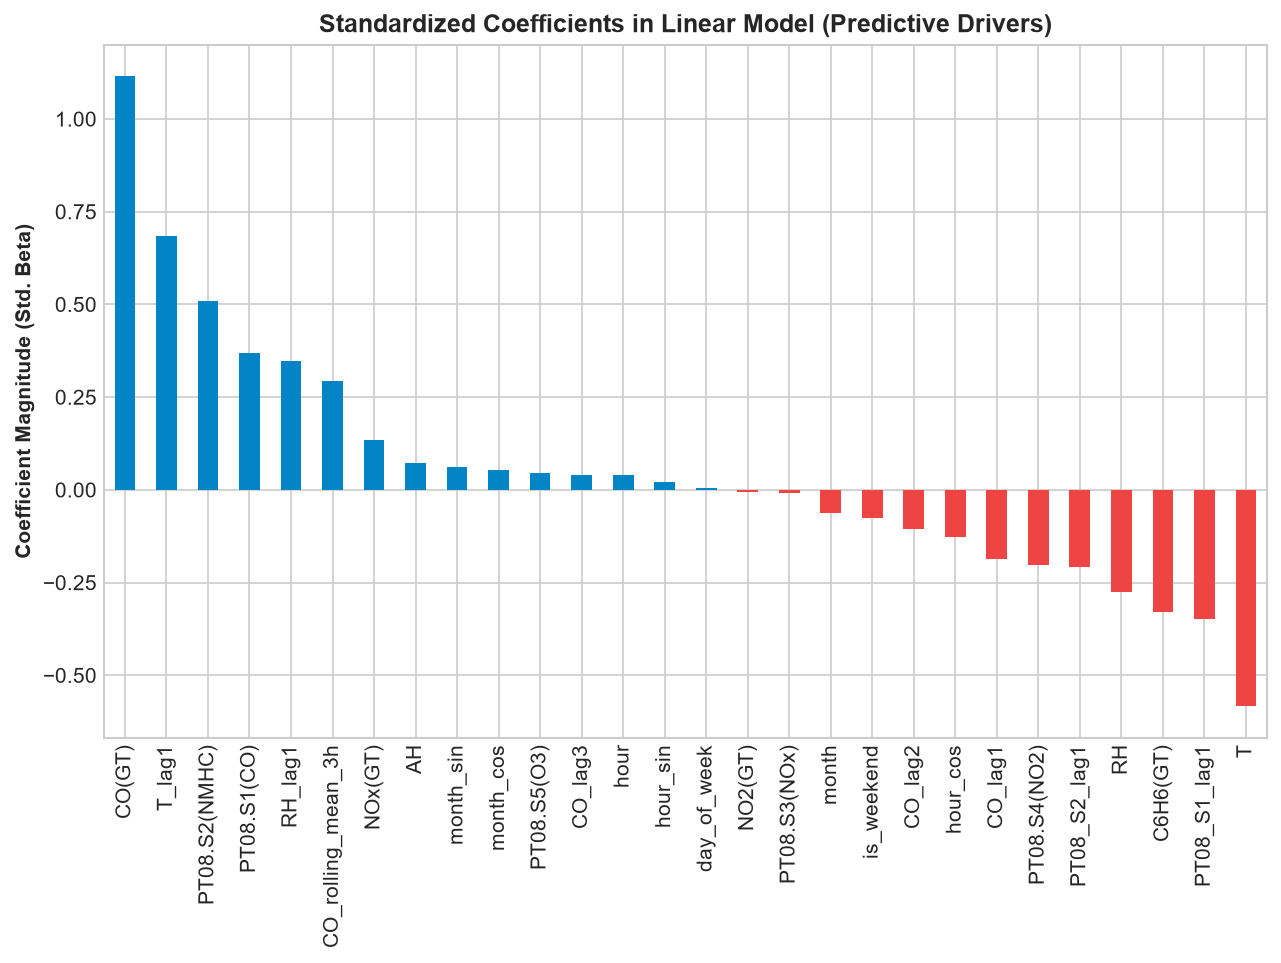

In [4]:
lin_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('regressor', LinearRegression())
])
lin_pipeline.fit(X_train, y_train)

ridge_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('regressor', Ridge(alpha=10.0))
])
ridge_pipeline.fit(X_train, y_train)

# Top coefficients
coef_series = pd.Series(lin_pipeline.named_steps['regressor'].coef_, index=features).sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(10, 6), dpi=150)
coef_series.plot(kind='bar', ax=ax, color=np.where(coef_series > 0, '#0284c7', '#ef4444'))
ax.set_title('Standardized Coefficients in Linear Model (Predictive Drivers)', fontsize=12, fontweight='bold')
ax.set_ylabel('Coefficient Magnitude (Std. Beta)', fontweight='bold')
plt.show()

## 5. Non-Linear Models: Random Forest & HistGradientBoosting

Tree-based ensembles capture complex non-linear meteorological interactions and sharp threshold shifts during rush hours.


In [5]:
rf_model = RandomForestRegressor(n_estimators=100, max_depth=12, random_state=42, n_jobs=-1)
rf_model.fit(X_train, y_train)

hgb_model = HistGradientBoostingRegressor(max_iter=100, max_depth=8, random_state=42)
hgb_model.fit(X_train, y_train)
print('Tree ensemble models calibrated.')

Tree ensemble models calibrated.


## 6. Comprehensive Model Comparison Table

Comparing candidate models on Validation (tuning criteria) and holdout Test sets.


In [6]:
model_dict = {
    'Persistence Baseline': None,
    'Linear Regression': lin_pipeline,
    'Ridge Regression': ridge_pipeline,
    'Random Forest': rf_model,
    'HistGradientBoosting': hgb_model
}

rows = []
for name, m in model_dict.items():
    if m is None:
        val_pred = X_val['CO(GT)']
        test_pred = X_test['CO(GT)']
    else:
        val_pred = m.predict(X_val)
        test_pred = m.predict(X_test)
        
    rows.append({
        'Model': name,
        'Val RMSE': round(root_mean_squared_error(y_val, val_pred), 4),
        'Val MAE': round(mean_absolute_error(y_val, val_pred), 4),
        'Val R2': round(r2_score(y_val, val_pred), 4),
        'Test RMSE': round(root_mean_squared_error(y_test, test_pred), 4),
        'Test MAE': round(mean_absolute_error(y_test, test_pred), 4),
        'Test R2': round(r2_score(y_test, test_pred), 4)
    })

comparison_df = pd.DataFrame(rows)
comparison_df

,Model,Val RMSE,Val MAE,Val R2,Test RMSE,Test MAE,Test R2
0,Persistence Baseline,0.7832,0.4908,0.7591,0.7739,0.4996,0.6556
1,Linear Regression,0.7698,0.5776,0.7673,0.7556,0.6035,0.6717
2,Ridge Regression,0.7761,0.5857,0.7634,0.7641,0.6156,0.6642
3,Random Forest,0.6806,0.4734,0.8181,0.5969,0.4232,0.7951
4,HistGradientBoosting,0.6619,0.4392,0.8279,0.5516,0.3841,0.8250


## 7. Residual Diagnostics for Candidate Model (`HistGradientBoosting`)

Analyzing prediction error properties: normality of residuals, variance homogeneity (homoscedasticity), and systematic under/over-prediction.


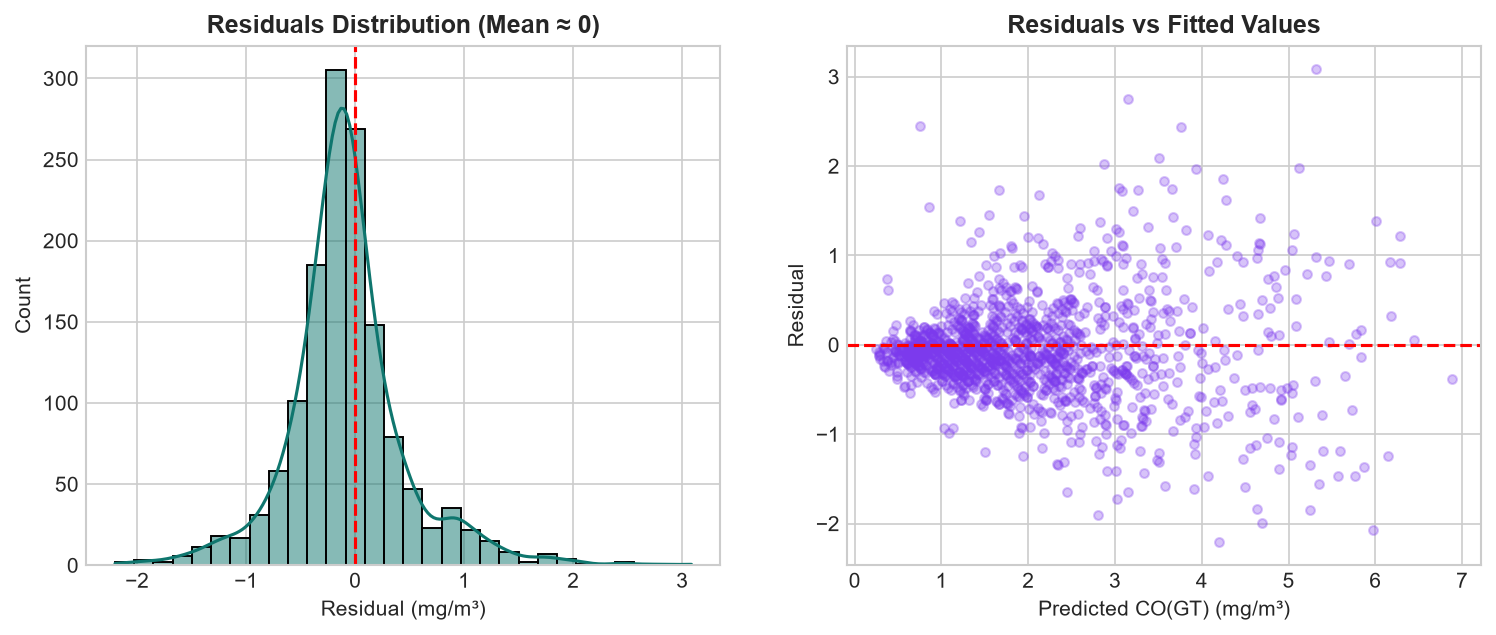

In [7]:
y_test_pred = hgb_model.predict(X_test)
residuals = y_test - y_test_pred

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5), dpi=150)
sns.histplot(residuals, kde=True, color='#0f766e', ax=ax1, bins=30)
ax1.axvline(0, color='red', linestyle='--')
ax1.set_title('Residuals Distribution (Mean ≈ 0)', fontweight='bold')
ax1.set_xlabel('Residual (mg/m³)')

ax2.scatter(y_test_pred, residuals, alpha=0.3, color='#7c3aed', s=18)
ax2.axhline(0, color='red', linestyle='--')
ax2.set_title('Residuals vs Fitted Values', fontweight='bold')
ax2.set_xlabel('Predicted CO(GT) (mg/m³)')
ax2.set_ylabel('Residual')
plt.show()

## 8. Modelling Summary & Selection Conclusion

- **Benchmark:** The persistence baseline sets a solid bar ($R^2 = 0.7591$ on validation, $R^2 = 0.6556$ on test).
- **Linear/Ridge:** Improve slightly in $R^2$ ($0.7673$ on val) and illuminate driving features (`CO(GT)`, sensor lags, and temperature).
- **Ensembles:** Tree models dominate. **`HistGradientBoostingRegressor`** achieves the highest Validation $R^2$ (**0.8279**) and lowest Validation RMSE (**0.6619 mg/m³**), outperforming all other models.
- **Candidate for Phase 6:** We advance **`HistGradientBoostingRegressor`** to Phase 6 for time-series cross-validated hyperparameter tuning and serialization.
